Practical task

1.Load breast cancer classification dataset from scikit-learn

2.Train a Decision Tree, Random Forest and Gradient Boosting model (use the same split and metric for a fair comparison)   

3.Tune Random Forest hyperparameters and report the best combination   

4.Compare ROC-AUC, F1 or another task-appropriate metric for all models

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.metrics import roc_curve, accuracy_score, roc_auc_score, f1_score
from sklearn.model_selection import GridSearchCV

#Load data
df = load_breast_cancer(as_frame=True)
X = df.data
y = df.target

X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [89]:
#Check data quality
print("Missing data:", X.isnull().sum().sum())
print("Number of duplicates:", X.duplicated().sum())

Missing data: 0
Number of duplicates: 0


In [90]:
# We do same split for all models
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [91]:
#We define and train models here
models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier()}

#Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)
    print("Model:", name, ". Accuracy:", accuracy)

Model: Decision Tree . Accuracy: 0.9035087719298246
Model: Random Forest . Accuracy: 0.9473684210526315
Model: Gradient Boosting . Accuracy: 0.956140350877193


In [92]:
# We tune here hyperparameters for Random Forest using GridSearchCV
random_forest = RandomForestClassifier(random_state=42, n_jobs=-1)
params = {
    'n_estimators': [45, 50, 100, 200],
    'max_depth': [None, 1, 2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 5],
}
#Searching for best hyperparameters
grid_search = GridSearchCV(estimator=random_forest, param_grid=params, cv=5, 
                           n_jobs=-1, scoring='roc_auc')

grid_search.fit(X_train, y_train)
#Best results
print("Best Parameters:", grid_search.best_params_)
print("Best CV ROC AUC:", grid_search.best_score_)

models["Updated Random Forest"] = grid_search.best_estimator_ #Here we add tunned model for comparison

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 50}
Best CV ROC AUC: 0.9905056759545923


In [93]:
#Comparing ROC AUC and F1 Score for all models
results = []

for name, model in models.items():
    y_pred = model.predict(X_test) #f1 predictions
    y_proba = model.predict_proba(X_test)[:, 1] #roc_auc probabilities

    results.append({'Model': name,'Accuracy': accuracy_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba),'F1 Score': f1_score(y_test, y_pred)})
    
results_df = pd.DataFrame(results).sort_values(by='ROC AUC', ascending=False)
results_df.round(4)

,Model,Accuracy,ROC AUC,F1 Score
3,Updated Random Forest,0.9561,0.9940,0.9655
1,Random Forest,0.9474,0.9927,0.9583
2,Gradient Boosting,0.9561,0.9907,0.9660
0,Decision Tree,0.9035,0.9087,0.9209


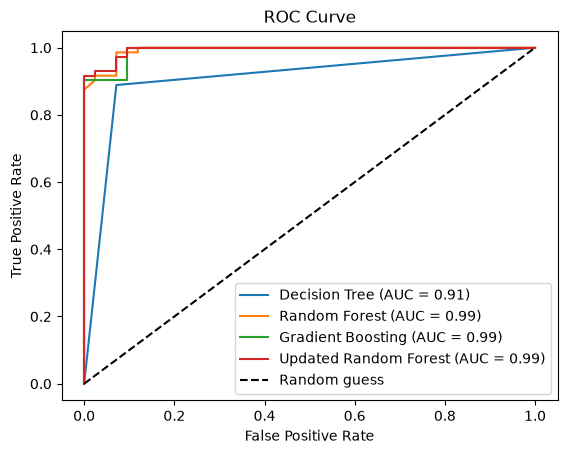

In [94]:
#plotting ROC curves
for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})')
    
plt.plot([0, 1], [0, 1], 'k--', label='Random guess') #Random guess line
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

Conclusion:

Single decision tree performs the worst, because one tree can overfit easily.

ROC AUC and f1 are better than standart accuracy, because f1 and ROC AUC shows how well it tells cancer and non cancer cases apart, which is very important in this case.

Gradient boosting and Random forest combine many trees and perform very well.